In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

dossier = "/content/drive/MyDrive/Projet_UA2/images_v2"

print(os.listdir(dossier))

['images_V2.zip', 'images_V2']


In [5]:
import os

print(os.listdir(extract_path))

['0', '1', '2']


In [6]:
import shutil
import os

local_path = "/content/images_V2"

if not os.path.exists(local_path):
    shutil.copytree(extract_path, local_path)

print("Copie terminée !")

Copie terminée !


In [7]:
import os

for classe in sorted(os.listdir(local_path)):
    chemin = os.path.join(local_path, classe)

    if os.path.isdir(chemin):
        images = [
            f for f in os.listdir(chemin)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(f"Classe {classe} : {len(images)} images")

Classe 0 : 364 images
Classe 1 : 405 images
Classe 2 : 396 images


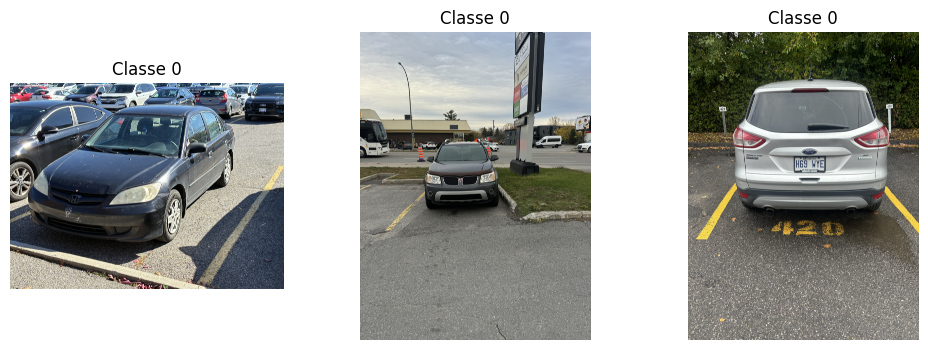

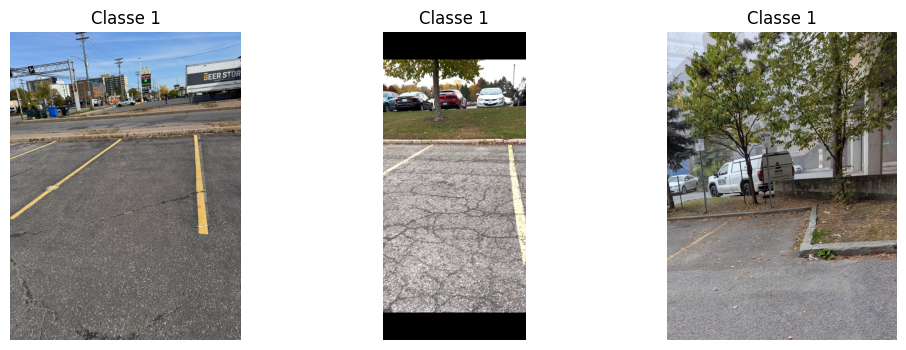

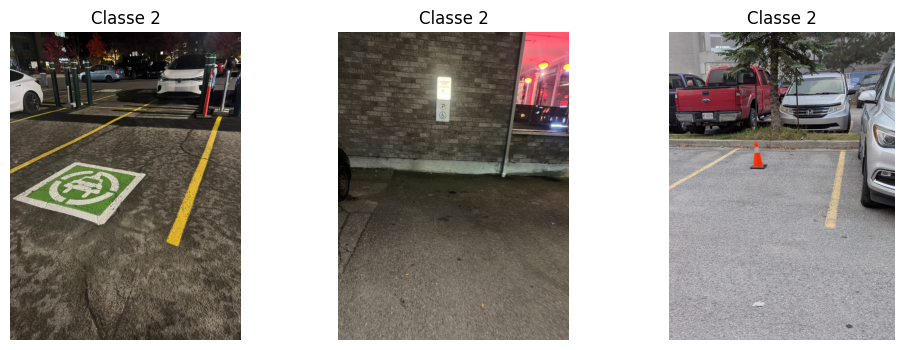

In [10]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Afficher 3 images par classe
for classe in ["0", "1", "2"]:
    dossier_classe = os.path.join(local_path, classe)
    fichiers = os.listdir(dossier_classe)[:3]

    plt.figure(figsize=(12, 4))

    for i, fichier in enumerate(fichiers):
        chemin = os.path.join(dossier_classe, fichier)
        image = Image.open(chemin)

        plt.subplot(1, 3, i + 1)
        plt.imshow(image)
        plt.title(f"Classe {classe}")
        plt.axis("off")

    plt.show()

In [11]:
from PIL import Image
import os

dimensions = {}

for classe in ["0", "1", "2"]:
    dossier_classe = os.path.join(local_path, classe)

    for fichier in os.listdir(dossier_classe):
        chemin = os.path.join(dossier_classe, fichier)

        try:
            image = Image.open(chemin)
            dimensions[image.size] = dimensions.get(image.size, 0) + 1
        except:
            pass

print("Dimensions des images :")

for dimension, nombre in dimensions.items():
    print(f"{dimension} : {nombre} images")

Dimensions des images :
(5712, 4284) : 61 images
(4284, 5712) : 71 images
(1500, 2000) : 40 images
(4000, 3000) : 168 images
(960, 1280) : 100 images
(899, 1599) : 1 images
(3024, 4032) : 59 images
(2144, 3768) : 1 images
(784, 984) : 1 images
(591, 1280) : 35 images
(3840, 5120) : 34 images
(1536, 2048) : 148 images
(4032, 3024) : 19 images
(4080, 3072) : 43 images
(2344, 1552) : 1 images
(2760, 2712) : 1 images
(1204, 1600) : 4 images
(2456, 2205) : 1 images
(1530, 2040) : 3 images
(2072, 3000) : 1 images
(1904, 2528) : 1 images
(1080, 1920) : 25 images
(3000, 936) : 1 images
(725, 1280) : 2 images
(2080, 3304) : 1 images
(908, 2016) : 21 images
(1263, 1579) : 1 images
(1332, 2048) : 1 images
(1200, 1600) : 71 images
(1660, 3952) : 1 images
(1126, 2000) : 1 images
(1599, 603) : 1 images
(2803, 2653) : 1 images
(1512, 2016) : 14 images
(2048, 1536) : 14 images
(2448, 2832) : 1 images
(3172, 1072) : 1 images
(907, 2016) : 1 images
(1180, 2048) : 1 images
(2664, 2696) : 1 images
(1033, 

In [12]:
from collections import Counter

largeurs = []
hauteurs = []

for classe in ["0", "1", "2"]:
    dossier_classe = os.path.join(local_path, classe)

    for fichier in os.listdir(dossier_classe):
        chemin = os.path.join(dossier_classe, fichier)

        try:
            with Image.open(chemin) as image:
                largeur, hauteur = image.size
                largeurs.append(largeur)
                hauteurs.append(hauteur)
        except:
            pass

print("Largeur minimale :", min(largeurs))
print("Largeur maximale :", max(largeurs))
print("Hauteur minimale :", min(hauteurs))
print("Hauteur maximale :", max(hauteurs))

Largeur minimale : 198
Largeur maximale : 5712
Hauteur minimale : 292
Hauteur maximale : 5712


In [13]:
from torchvision import transforms

image_size = 224

transformations = transforms.Compose([
    transforms.Resize(image_size),
    transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [14]:
from torchvision import datasets

dataset = datasets.ImageFolder(
    root=local_path,
    transform=transformations
)

print("Nombre total d'images :", len(dataset))
print("Classes :", dataset.classes)
print("Correspondance :", dataset.class_to_idx)

Nombre total d'images : 1165
Classes : ['0', '1', '2']
Correspondance : {'0': 0, '1': 1, '2': 2}


In [16]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Indices de toutes les images et leurs classes
indices = list(range(len(dataset)))
labels = dataset.targets

# Première séparation : 70 % entraînement, 30 % temporaire
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Deuxième séparation : 15 % validation, 15 % test
temp_labels = [labels[i] for i in temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# Création des trois ensembles
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)
test_dataset = Subset(dataset, test_indices)

print("Entraînement :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test :", len(test_dataset))

Entraînement : 815
Validation : 175
Test : 175
